# ANA-067 — How empirical do the production landscapes look?

**EXP-066 / RUN-172.** A comparison of 63 measured assay landscapes with the public
Adapt-Env thermodynamic generator. The scientific target is useful aggregate
resemblance for a synthetic online ML environment—not recovery of specific
empirical interactions or a universal model of protein biology.

One global readout is fitted per assay and arm. Calibration uses only fitness
quantiles, mean within-cube standard deviation, and near-floor mass. **WHT,
diminishing returns, and topology are withheld.** Confirmation uses disjoint
measured genotypes and 16 fresh synthetic seeds. There are no scientific
acceptance gates. The model family has seen some of these assay classes during
development; this is not a wholly unseen-biology discovery test.

Run this notebook top to bottom, or run `python notebooks/execute.py` from this
ANA directory with `notebooks/requirements.txt` installed. Restore the linked
RUN-172 DVC directory first if absent. Every figure is generated below and
exported as both PNG and PDF.

In [1]:
from pathlib import Path
import sys, json
from IPython.display import display
from IPython import get_ipython
get_ipython().run_line_magic('matplotlib', 'inline')
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'labproject.yaml').exists())
ANA = ROOT / 'analyses/2026-10-08_ANA-067_run-172-production-landscape-aggregate-realism'
sys.path.insert(0, str(ANA / 'notebooks'))
import analysis_tools as tools
import numpy as np
import pandas as pd
print('Raw data:', tools.DATA)
print('Figures:', tools.FIGURES)

Raw data: /Users/matthewspence/Documents/Documents/project-adapt-env/data/processed/production_landscapes/RUN-172
Figures: /Users/matthewspence/Documents/Documents/project-adapt-env/analyses/2026-10-08_ANA-067_run-172-production-landscape-aggregate-realism/figures


## 1. Audit the frozen experiment before interpreting it

The audit verifies all output and source hashes, source/API readout identities,
all selected objective values, disjoint calibration/confirmation genotypes and
fresh seeds. It independently recomputes the WHT with a centered butterfly
transform, fixed-direction slopes and sign epistasis from raw cube values.
Very small powers can make fractions sensitive to floating-point cancellation;
these discrepancies receive explicit propagated roundoff bounds and are saved.

Three final excluded FLIP inventory rows were omitted by the RUN's last CSV
flush. The analysis restores those rows in a **derived** inventory table. The
frozen RUN remains unchanged. Statistical availability is not evidence of fit.

In [2]:
stats, fits, suitability, audit = tools.audit()
display(pd.Series(audit, name='audit'))
display(suitability.groupby('status').size().rename('inventory entries'))

Audited 10 of 63 assays


Audited 20 of 63 assays


Audited 30 of 63 assays


Audited 40 of 63 assays


Audited 50 of 63 assays


Audited 60 of 63 assays


output_hashes                                                                    1819
source_hashes                                                                      12
restored_inventory_rows             [flip_aav_full_data, flip_gb1_four_mutations_f...
evaluated_assays                                                                   63
fitted_settings                                                                   195
statistic_rows                                                                 179310
empirical_nodes                                                                 23016
replayed_intrinsic_nodes                                                       230400
public_API_replayed_nodes                                                         368
losses_recomputed                                                                 195
roundoff_sensitive_fraction_rows                                                   65
inference                           Numerical/provenan

status
constant_calibration                    1
evaluated                              63
insufficient_complete_cube_coverage    15
out_of_scope_or_duplicate               7
Name: inventory entries, dtype: int64

## 2. Estimands and uncertainty

The main numerical resolution is **0.001 × each assay's calibration fitness
range**, with 1e-12 and 0.01 as sensitivities. This is a numerical comparison
scale, not a measured experimental detection limit.

- Equal-cube epistasis averages fractions only where cube variance is resolved.
- Pooled epistasis is the ratio of summed nonadditive power to summed total power.
- DR slopes regress a fixed-direction mutation effect on background fitness;
  means can be dominated by a small denominator. Beneficial-mutation and median
  diagnostics remain separate.
- 95% percentile bootstrap intervals resample empirical **cubes**, or synthetic
  **seeds**. Repeated observation draws are not independent landscapes.

The bootstrap is conditional on selected cubes and fitted parameters; it does
not refit calibration or account for dependence among related assays. The 50
stability assays dominate the count, so family summaries are kept separate.
Model length means variable library coordinates, not whole-protein length.

In [3]:
estimates, comparisons, marginal, bootstrap = tools.summarize(stats, fits, draws=1500)
primary = comparisons[comparisons.observation.eq('none')]
summary = primary.assign(absolute_error=lambda d: abs(d.difference)).groupby(['family','arm','metric']).absolute_error.median().unstack('metric')
display(summary[['epistatic_fraction','ho_fraction','slope','sign_epistasis_fraction']])
print('Full numerical tables are saved in', tools.TABLES)

metric                         epistatic_fraction  ho_fraction     slope  \
family             arm                                                     
Function / binding r0_sigmoid            0.072771     0.075783  0.897231   
                   r4_linear             0.179886     0.051854  0.355469   
                   r4_sigmoid            0.158793     0.060591  0.369666   
Stability          r0_sigmoid            0.096358          NaN  0.663686   
                   r4_linear             0.082573          NaN  0.681161   
                   r4_sigmoid            0.078177          NaN  0.779428   

metric                         sign_epistasis_fraction  
family             arm                                  
Function / binding r0_sigmoid                 0.406250  
                   r4_linear                  0.227539  
                   r4_sigmoid                 0.112630  
Stability          r0_sigmoid                 0.393601  
                   r4_linear                  0.312500  
                   r4_sigmoid                 0.320312

Full numerical tables are saved in /Users/matthewspence/Documents/Documents/project-adapt-env/analyses/2026-10-08_ANA-067_run-172-production-landscape-aggregate-realism/tables


## Figure 1 — Coverage and what calibration actually recovered

The scope panel includes every inventory entry. Calibration objective and
held-out quantile error are different quantities and should not be read as a
train–test equality plot. Local-spread ratios expose failures that a plausible
marginal fitness histogram could hide.

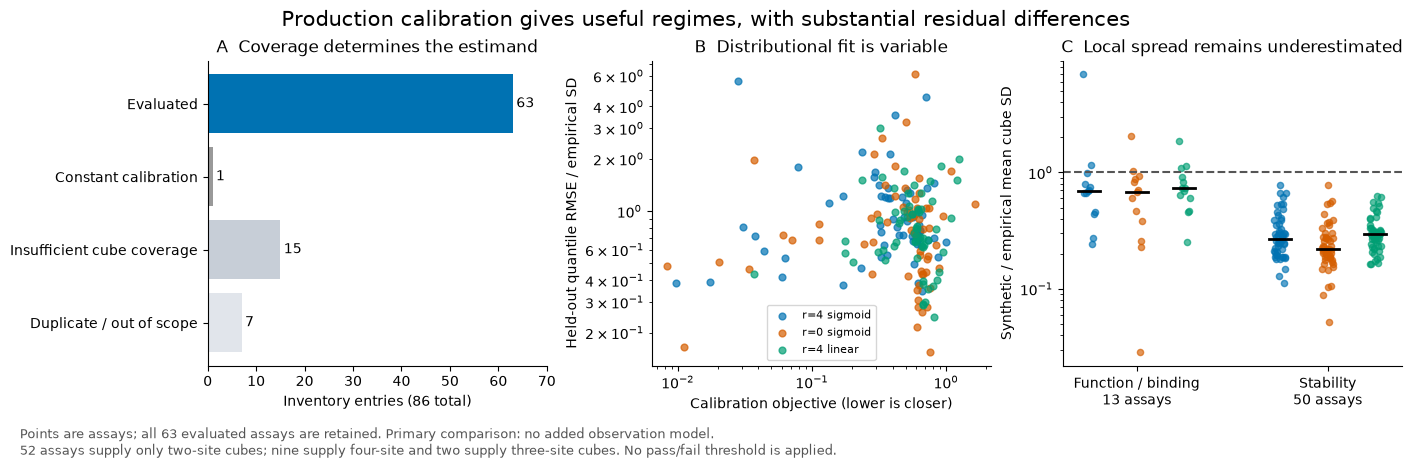

In [4]:
tools.scope_calibration(suitability, marginal, fits)

## Figure 2 — Statistics deliberately withheld from calibration

Each point is one assay/arm, with dimension-matched empirical and synthetic
sampling. Faint uncertainty bars accompany the r=4 sigmoid. The diagonal is a
reference for resemblance, not a decision boundary. Two-site assays contribute
no evidence about order-three or order-four epistasis.

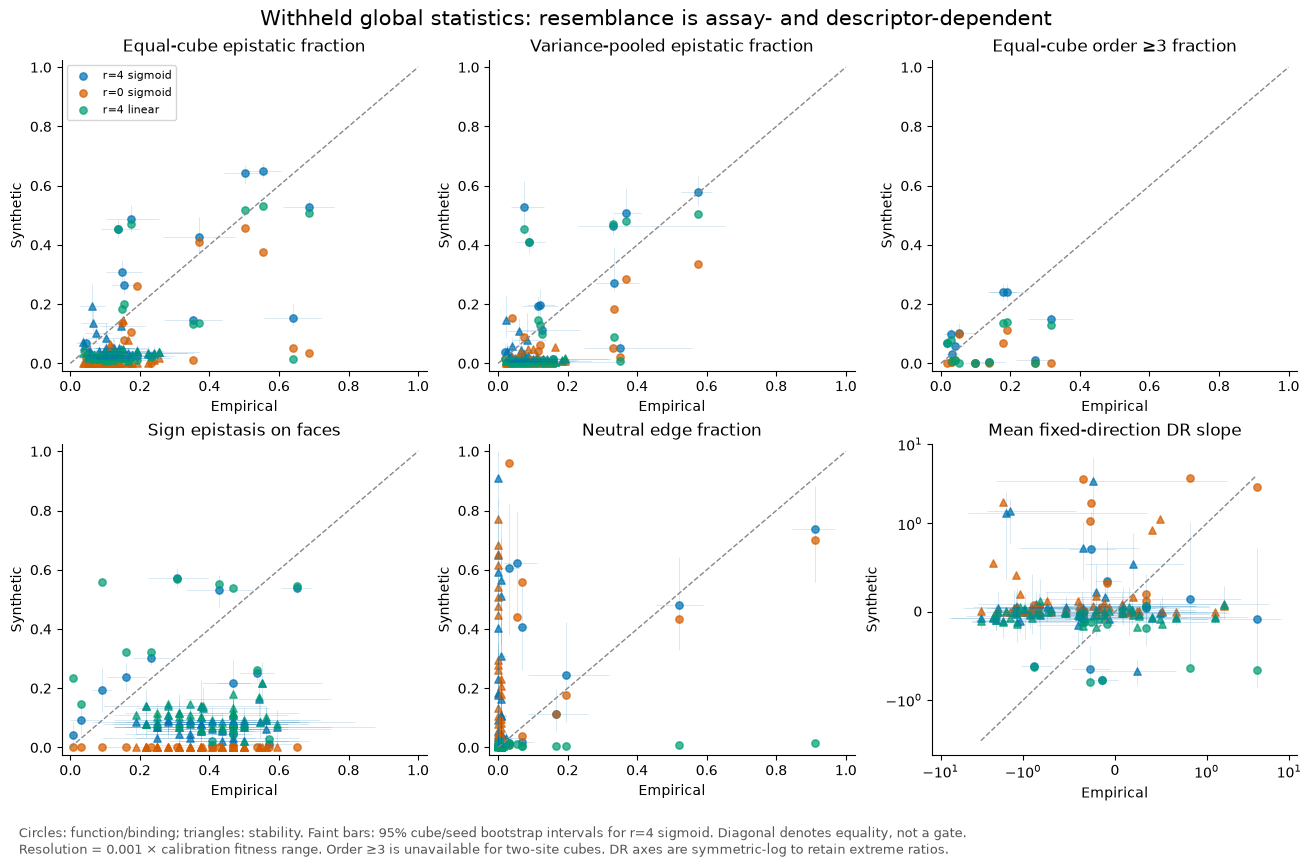

In [5]:
tools.global_statistics(comparisons)

## Figure 3 — All assays, including the mismatches

This atlas shows signed deviations for the primary r=4 sigmoid with no added
observation model. Rows are grouped by family and sorted by label, never by
fit quality. Grey higher-order cells are **unavailable**, not zero. The colour
ranges differ by metric; clipped values are marked and retained exactly in the
CSV. This is a descriptive view, not a composite biological-realism score.

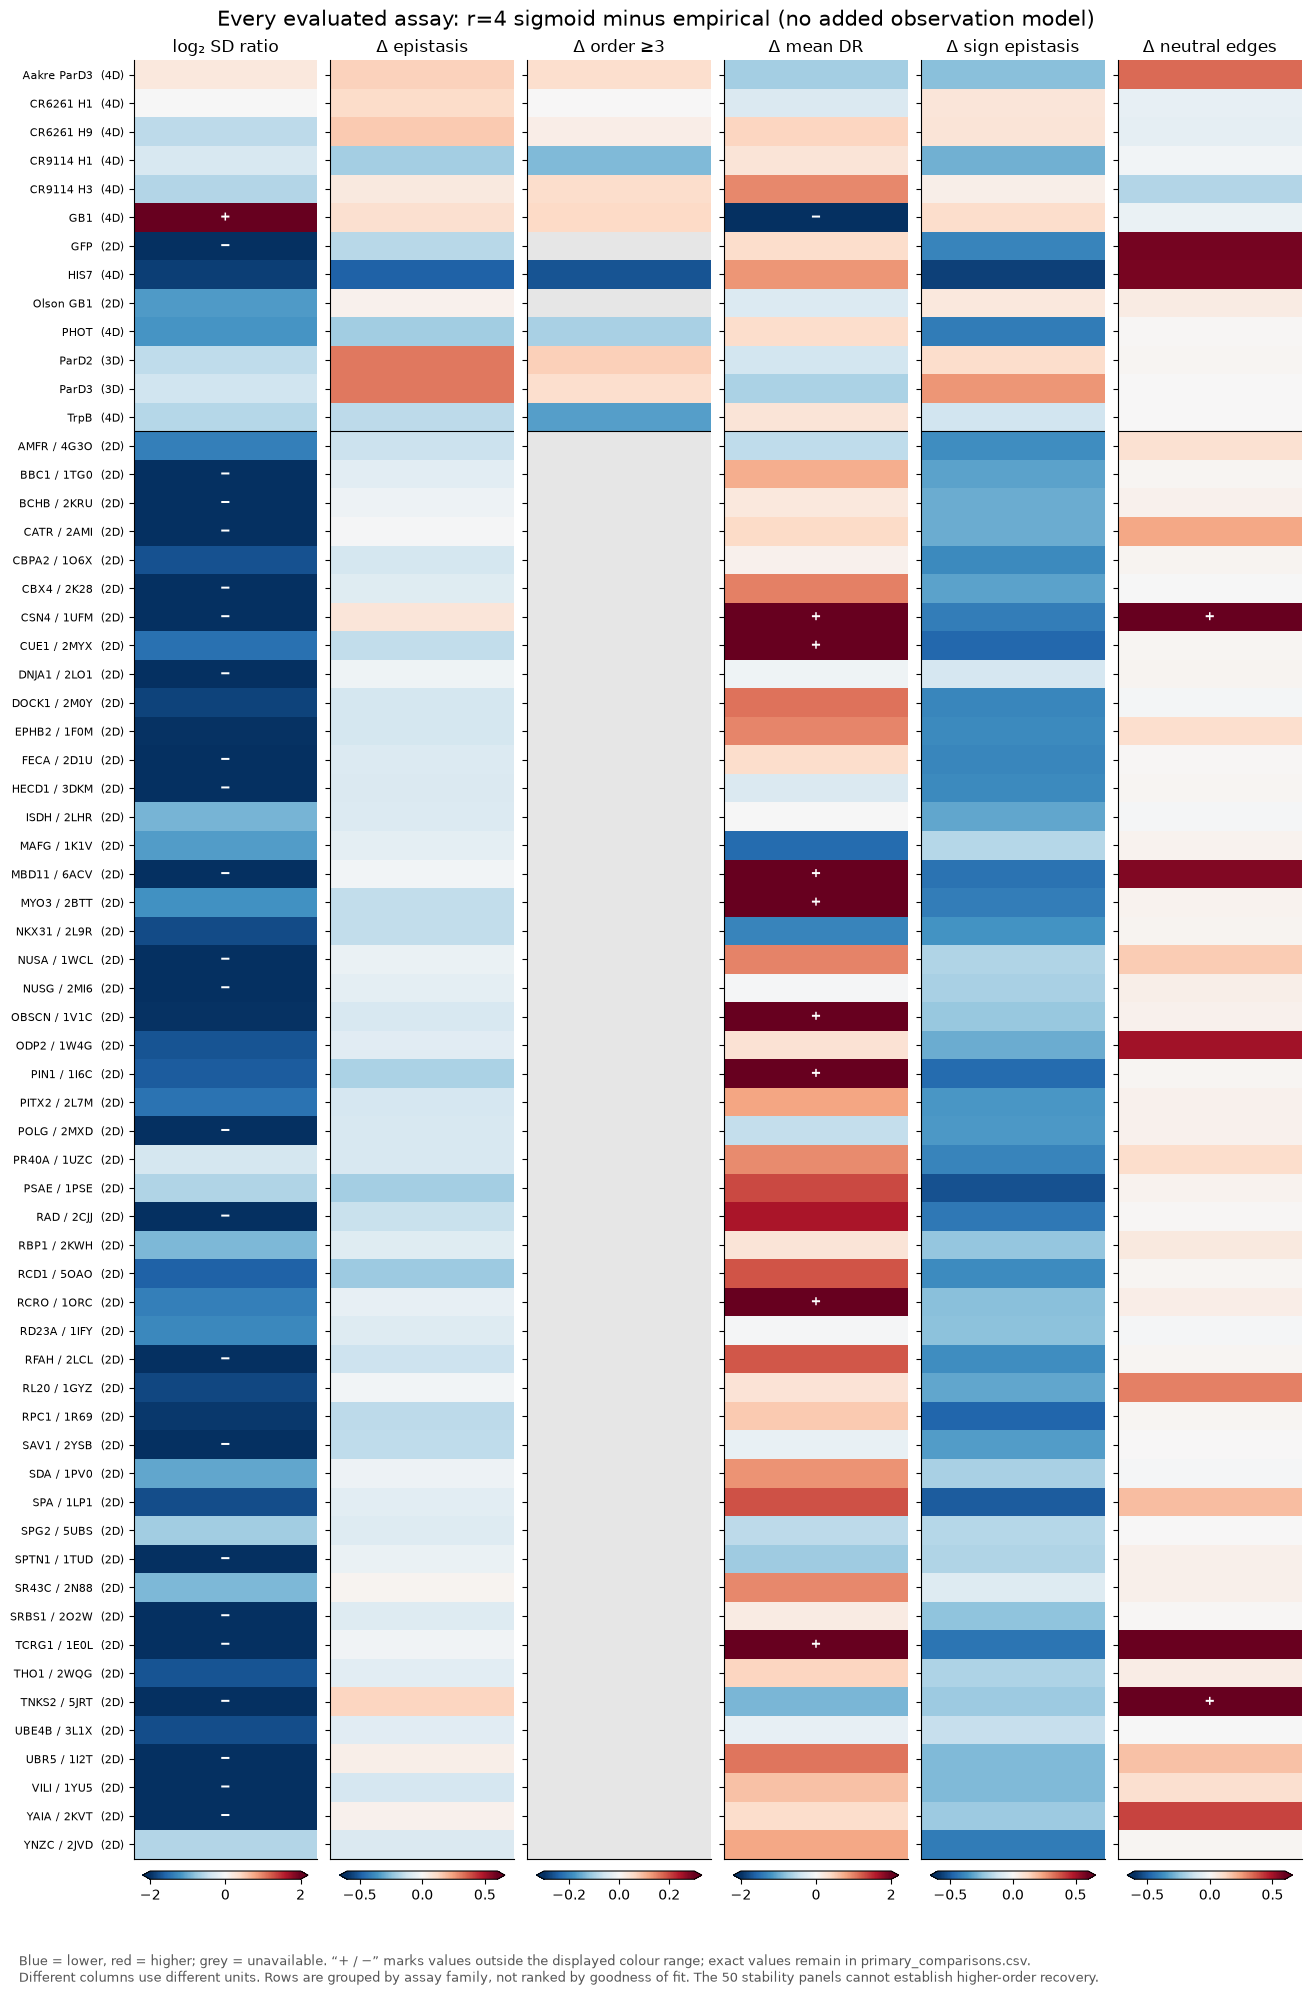

In [6]:
tools.residual_atlas(comparisons)

## Figure 4 — What the fitness distributions and local spread look like

Five examples are the protocol's pre-production smoke systems; GB1 is added
explicitly to illustrate seed/split sensitivity. Every confirmation cube and
seed enters each curve. No visually favorable sequence or seed is chosen.
The synthetic comparison targets the sampled library geometry, not an
unmeasured full protein sequence space.

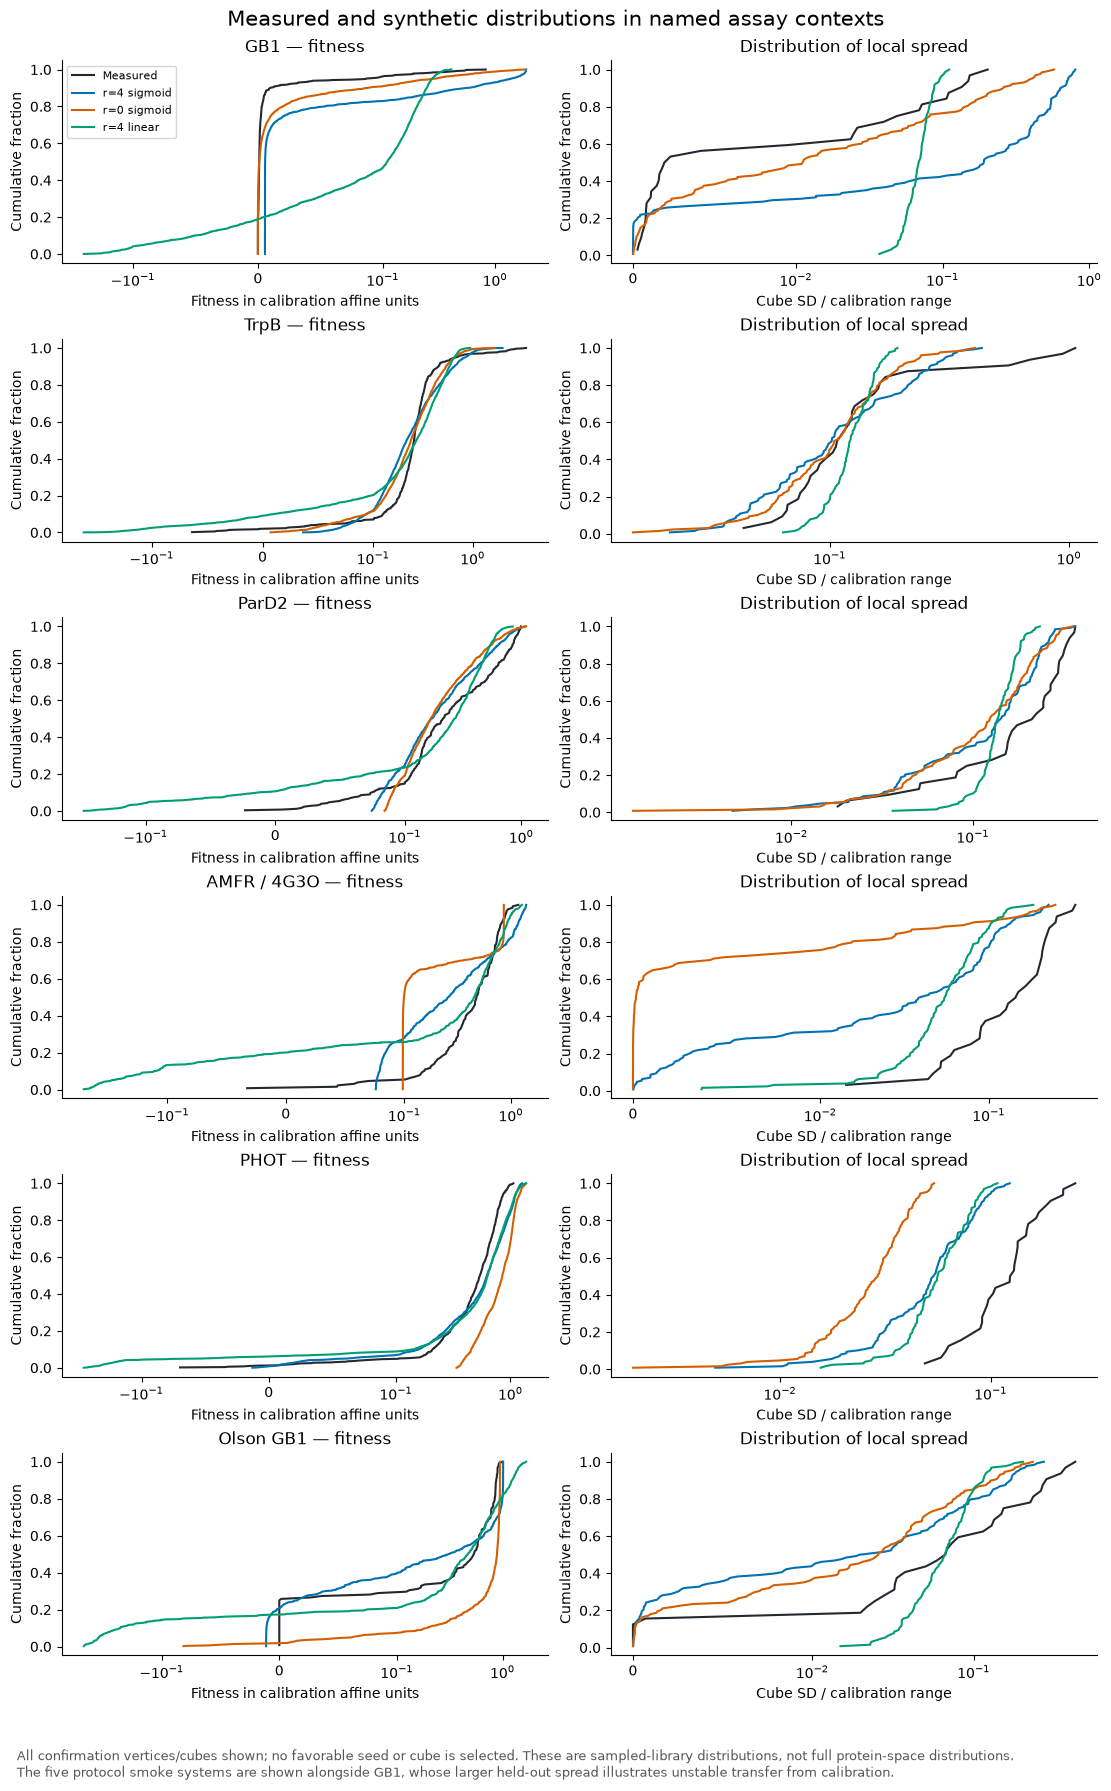

In [7]:
tools.examples(fits)

## Figure 5 — TrpB: distinguish intrinsic structure from the observation process

Observed predictions are filled points; the corresponding intrinsic maps are
hollow points. TrpB is the only production assay with a matched replicate/control
observation sensitivity here. A good observed match under shared-stop covariance
does not uniquely identify intrinsic epistasis or a physical thermodynamic
mechanism. No equivalent noise decomposition is available for the other assays.

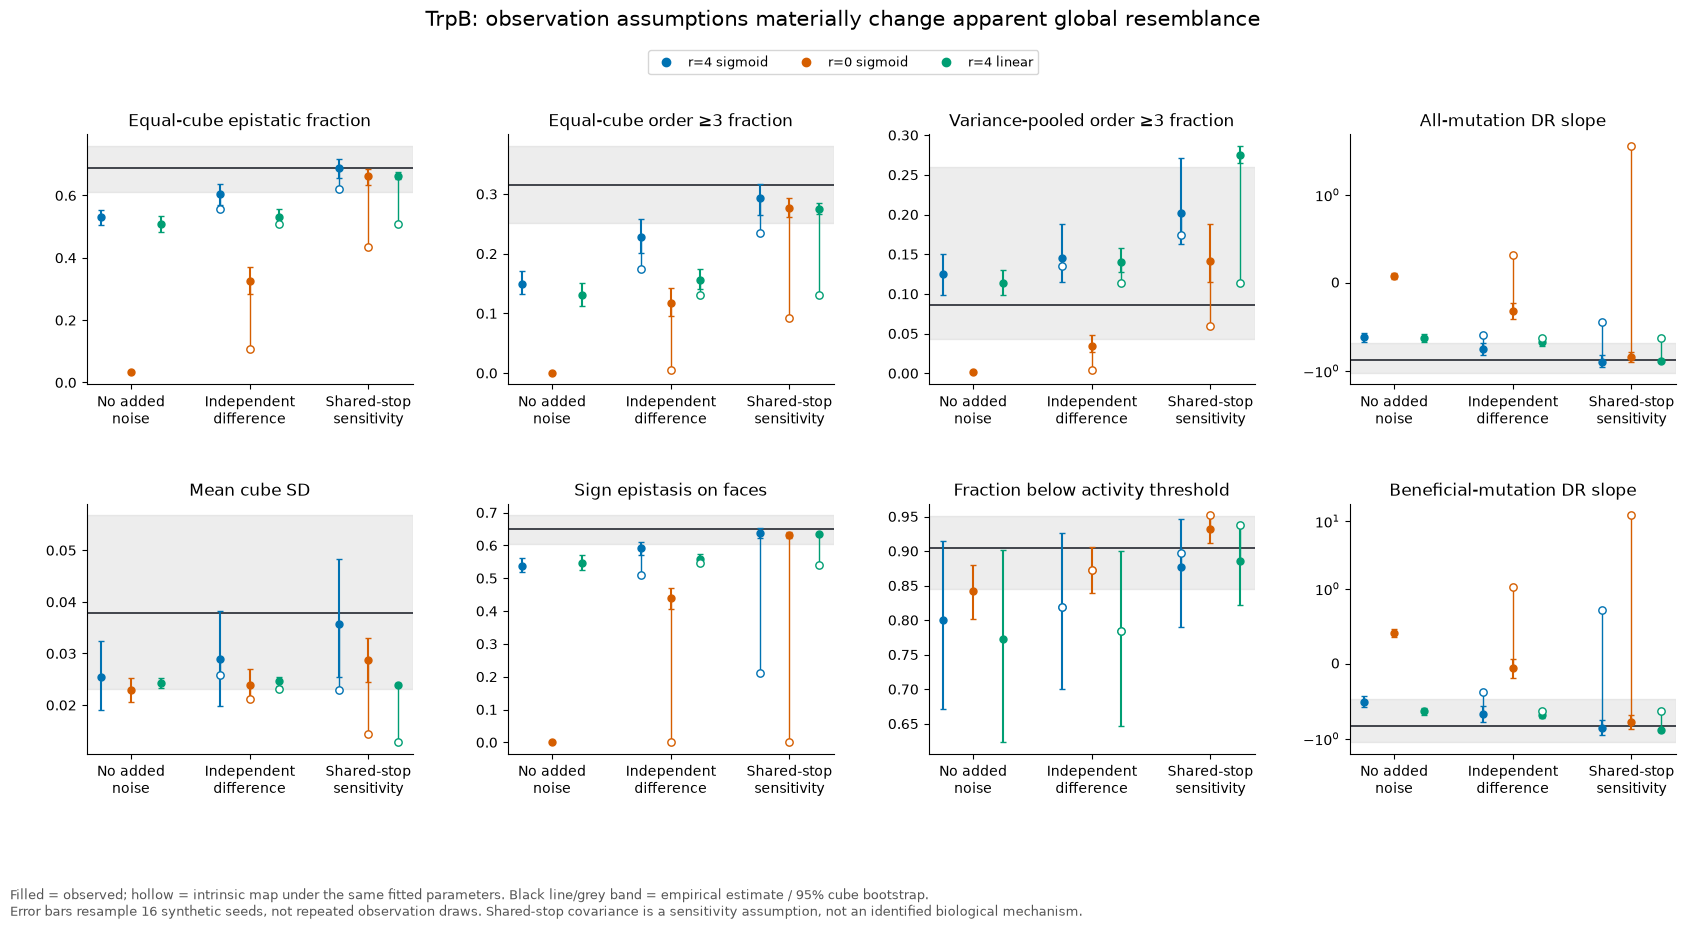

In [8]:
tools.trpb_observation(estimates)

## Figure 6 — Diminishing returns needs a denominator and a sampling context

A two-site cube has only two backgrounds per mutation. Large slope means can
therefore reflect unstable ratios rather than a reproducible biological rate.
Show resolution dependence and median diagnostics alongside the requested mean;
neither replaces the other retrospectively.

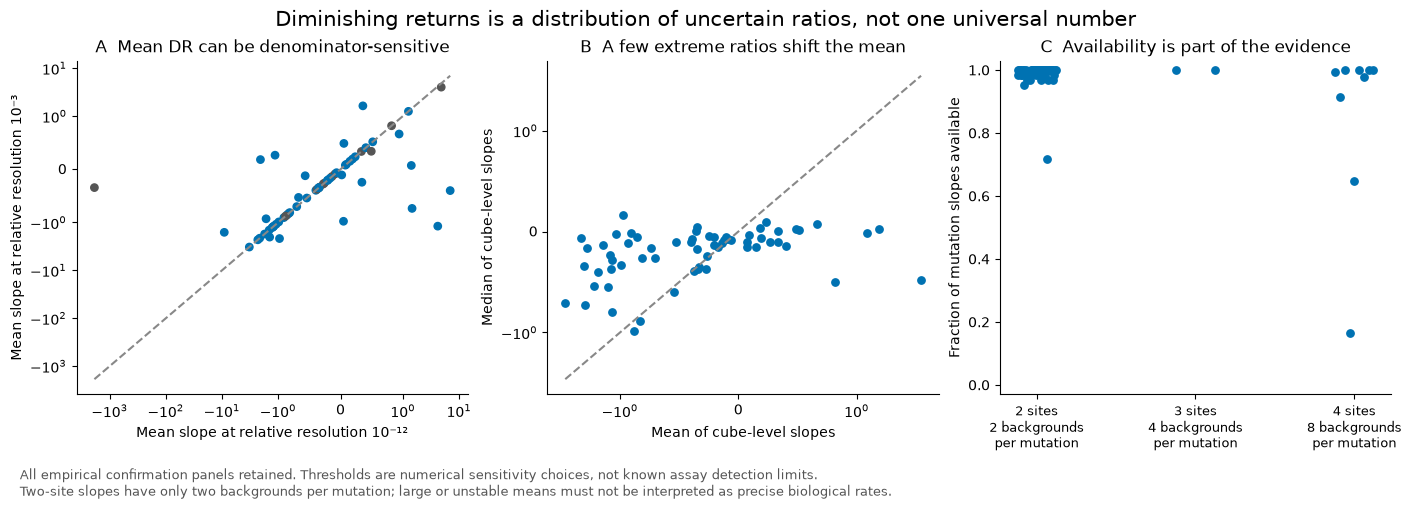

In [9]:
tools.resolution_diagnostics(estimates, stats)

## Numerical interpretation tables

These tables retain continuous differences rather than introducing a pass/fail
criterion. Optimizer convergence and proximity to bounds qualify the finite
search; they do not certify an optimum or imply that no better model parameters
exist. The public r=0 and r=4 settings are both supplied in portable form.

In [10]:
m = marginal[marginal.observation.eq('none') & marginal.split.eq('confirmation')]
display(m.groupby(['family','arm'])[['quantile_nrmse','sd_ratio','calibration_loss']].median())
t = estimates[estimates.dataset_id.eq('trpb_johnston2024_four_site_graphfla') & estimates.split.eq('confirmation') & estimates.relative_resolution.eq(.001)]
display(t[t.metric.isin(['epistatic_fraction','ho_fraction','slope','sd_fitness','near_floor_fraction'])].pivot_table(index=['observation','arm'],columns='metric',values='estimate'))
print('Finite-budget fits converged:', sum(s['optimizer_converged'] for s in fits), '/', len(fits))
print('Fits within 1% of at least one bound:', sum(min(s['relative_boundary_distance']) < .01 for s in fits))
backup = json.loads((tools.TABLES / 'data_bundle_audit.json').read_text())
assert backup['all_md5_match']
display(pd.Series(backup, name='DVC backup'))

quantile_nrmse  sd_ratio  calibration_loss
family             arm                                                   
Function / binding r0_sigmoid        0.683032  0.675017          0.070831
                   r4_linear         0.888903  0.732954          0.340030
                   r4_sigmoid        0.593067  0.695989          0.059621
Stability          r0_sigmoid        0.783811  0.220301          0.612458
                   r4_linear         0.733075  0.295176          0.611870
                   r4_sigmoid        0.832988  0.269954          0.512553

metric                                        epistatic_fraction  ho_fraction  \
observation                       arm                                           
independent_difference            r0_sigmoid            0.324614     0.118083   
                                  r4_linear             0.531518     0.156178   
                                  r4_sigmoid            0.603388     0.228727   
independent_difference_intrinsic  r0_sigmoid            0.108486     0.004841   
                                  r4_linear             0.508099     0.129970   
                                  r4_sigmoid            0.557400     0.173541   
measured                          empirical             0.687570     0.315613   
none                              r0_sigmoid            0.034152     0.000520   
                                  r4_linear             0.508099     0.129970   
                                  r4_sigmoid            0.529685     0.149369   
shared_stop_sensitivity           r0_sigmoid            0.661220     0.277294   
                                  r4_linear             0.663671     0.275694   
                                  r4_sigmoid            0.688662     0.293289   
shared_stop_sensitivity_intrinsic r0_sigmoid            0.434295     0.092608   
                                  r4_linear             0.508099     0.129970   
                                  r4_sigmoid            0.620612     0.235112   

metric                                        near_floor_fraction  sd_fitness  \
observation                       arm                                           
independent_difference            r0_sigmoid             0.872528    0.023955   
                                  r4_linear              0.784424    0.024603   
                                  r4_sigmoid             0.818604    0.028841   
independent_difference_intrinsic  r0_sigmoid             0.872559    0.021166   
                                  r4_linear              0.784668    0.023044   
                                  r4_sigmoid             0.819336    0.025800   
measured                          empirical              0.904297    0.037872   
none                              r0_sigmoid             0.842285    0.022976   
                                  r4_linear              0.772949    0.024271   
                                  r4_sigmoid             0.800293    0.025403   
shared_stop_sensitivity           r0_sigmoid             0.931824    0.028750   
                                  r4_linear              0.885223    0.023937   
                                  r4_sigmoid             0.877289    0.035780   
shared_stop_sensitivity_intrinsic r0_sigmoid             0.951660    0.014491   
                                  r4_linear              0.937012    0.012778   
                                  r4_sigmoid             0.896484    0.022902   

metric                                           slope  
observation                       arm                   
independent_difference            r0_sigmoid -0.318296  
                                  r4_linear  -0.669986  
                                  r4_sigmoid -0.753015  
independent_difference_intrinsic  r0_sigmoid  0.309183  
                                  r4_linear  -0.626323  
                                  r4_sigmoid -0.589414  
measured                          empirical  -0.880500  
none                              r0_sigmoid  0.073543  
                                  r4_linear  -0.626323  
                                  r4_sigmoid -0.620350  
shared_stop_sensitivity           r0_sigmoid -0.849077  
                                  r4_linear  -0.885259  
                                  r4_sigmoid -0.896091  
shared_stop_sensitivity_intrinsic r0_sigmoid  4.133233  
                                  r4_linear  -0.626323  
                                  r4_sigmoid -0.450943

Finite-budget fits converged: 76 / 195
Fits within 1% of at least one bound: 47


verified_objects                                                 1840
all_md5_match                                                    True
directory_md5                    521d0e1b381ead592b0f47504e0f13ba.dir
bytes                                                       227667682
files                                                            1842
remote_store        /tank/data/labproj/projects/project-adapt-env/...
Name: DVC backup, dtype: object

## Interpretation and limits

The results support a **parameterized synthetic family with useful empirical
regimes**, especially when assay observations are modeled explicitly. They do
not support treating the fixed r=4 production recipe as broadly interchangeable
with all empirical landscapes. Similar marginal fitness distributions are
insufficient when local variation, sign epistasis or diminishing returns differ.

The additive sigmoid control can express magnitude epistasis but cannot produce
intrinsic sign epistasis; the GNK component supplies real synthetic ruggedness.
The need for that capacity is distinct from demonstrating the correct frequency
and strength of ruggedness in every assay. The parameter search is deliberately
bounded and tests r=0 and r=4, so it cannot rule out useful intermediate regimes.

TrpB supplies a concrete observed-fit example, with a material observation-model
qualification. PHOT/HIS7 and the common shortfall in stability-panel local spread
are substantive boundaries on broad empirical resemblance. No claim of perfect
landscapes, fitted empirical interaction identities, or statistical invariance
at arbitrary length follows from these data.

The single-latent nonlinear description is consistent with [Otwinowski,
McCandlish & Plotkin (2018)](https://doi.org/10.1073/pnas.1804015115). Global
fitness-dependent effects can also arise from complex interactions, as shown by
[Reddy & Desai (2021)](https://doi.org/10.7554/eLife.64740); aggregate agreement
alone therefore does not identify a unique physical mechanism.

See `../analysis.md` for the concise figure-led interpretation, and `../tables/`
for exact assay-level estimates and uncertainty. These remain an ANA analysis;
no new RES or CLAIM is created.